In [1]:
import numpy as np
import cupy
from cupyx.scipy.sparse.linalg import LinearOperator

from reactmr.tran2d import Tran2DMotionOp, Tran2DReconstructor, run_react, Identity
from reactmr.cfftn import CupyCenteredFFTN
from reactmr.utils import get_roi_slice

import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import scienceplots

In [2]:
plt.style.use(['science', 'ieee'])
plt.rcParams.update({'figure.dpi': '300'})

In [3]:
class Tran2DSenseOperator(LinearOperator):

    def __init__(self, sz_im, ks, sens, gpu_id, stream):

        self.sz_im = sz_im
        self.ks = ks
        self.gpu_id = gpu_id
        self.stream = stream
        self.dtype = cupy.dtype("complex64")
        self.ncoil = sens.shape[0]
        self.fft_op = CupyCenteredFFTN(sz_im, gpu_id=gpu_id, stream=stream)
        self.h_sens = sens.copy()
        with cupy.cuda.Device(self.gpu_id), self.stream:
            self.d_sens = cupy.asarray(self.h_sens)

        self.shape = (self.ncoil * np.prod(sz_im), np.prod(sz_im))
        self.shape_data = (self.ncoil, *self.ks.shape, self.sz_im[1])

    def _matvec(self, x):
        return self.forward(x)

    def _rmatvec(self, x):
        return self.adjoint(x)

    def forward(self, x):

        with cupy.cuda.Device(self.gpu_id), self.stream:
            d_y = cupy.zeros(self.shape_data, dtype=cupy.complex64)

        xp = cupy.get_array_module(x)
        if xp is np:
            with cupy.cuda.Device(self.gpu_id), self.stream:
                d_x = cupy.asarray(x).reshape(self.sz_im)
        else:
            with cupy.cuda.Device(self.gpu_id), self.stream:
                d_x = x.reshape(self.sz_im)

        for coil_ind in range(self.ncoil):
            with cupy.cuda.Device(self.gpu_id), self.stream:
                d_sens_x = d_x * self.d_sens[coil_ind]

            d_ksp = self.fft_op.cfftn(d_sens_x)
            with cupy.cuda.Device(self.gpu_id), self.stream:
                for acq_ind in range(self.ks.shape[0]):
                    d_y[coil_ind, acq_ind] = d_ksp[self.ks[acq_ind]]

        with cupy.cuda.Device(self.gpu_id), self.stream:
            d_y = d_y.ravel()

        if xp is np:
            with cupy.cuda.Device(self.gpu_id), self.stream:
                y = cupy.asnumpy(d_y)
        else:
            y = d_y

        return y

    def adjoint(self, y):

        with cupy.cuda.Device(self.gpu_id), self.stream:
            d_x = cupy.zeros(self.sz_im, dtype=cupy.complex64)

        xp = cupy.get_array_module(y)
        if xp is np:
            with cupy.cuda.Device(self.gpu_id), self.stream:
                d_y = cupy.asarray(y).reshape(self.shape_data)
        else:
            with cupy.cuda.Device(self.gpu_id), self.stream:
                d_y = y.reshape(self.shape_data)

        for coil_ind in range(self.ncoil):
            with cupy.cuda.Device(self.gpu_id), self.stream:
                d_ksp = cupy.zeros(self.sz_im, dtype=cupy.complex64)

                for acq_ind in range(self.ks.shape[0]):
                    d_ksp[self.ks[acq_ind]] = d_y[coil_ind, acq_ind]

                d_im = self.fft_op.cifftn(d_ksp)
                d_x += cupy.conj(self.d_sens[coil_ind]) * d_im

        with cupy.cuda.Device(self.gpu_id), self.stream:
            d_x = d_x.ravel()

        if xp is np:
            with cupy.cuda.Device(self.gpu_id), self.stream:
                x = cupy.asnumpy(d_x)
        else:
            x = d_x

        return x

In [4]:
# ----- helper functions ----- #

def get_kspace_noise_multicoil(
    data_gt, ks, ws, snr_in_isp, recon_op, mask=None, cov=None, rng=None
):

    if rng is None:
        rng = np.random.default_rng()

    data_gt = np.asarray(data_gt)
    ncoil = data_gt.shape[0]
    sz_im = recon_op.sz_im

    if mask is None:
        roi = np.ones(sz_im, dtype=bool)
    else:
        mask = np.asarray(mask)
        if mask.shape != sz_im:
            raise ValueError("mask must have the same spatial shape as im_gt.")
        roi = mask > 0

    # generate white noise in k-space for each coil
    white_ksp = rng.normal(size=data_gt.shape) + 1j * rng.normal(size=data_gt.shape)

    # color noise across coils using covariance, if provided
    if cov is not None:
        cov = np.asarray(cov)
        if cov.shape != (ncoil, ncoil):
            raise ValueError("cov must have shape (ncoil, ncoil).")
        # Cholesky factor: cov = L L^H
        L = np.linalg.cholesky(cov)

        # Apply L to the coil dimension for all voxels at once
        # Reshape to (ncoil, Nvox), multiply, then reshape back
        white_flat = white_ksp.reshape(ncoil, -1)
        colored_flat = L @ white_flat
        noise_ksp = colored_flat.reshape(white_ksp.shape)
    else:
        noise_ksp = white_ksp

    # sum-of-squares coil combination
    recon_op.prep(data_gt, ks, ws)
    signal_comb = recon_op.recon(to_host=True)
    
    recon_op.prep(noise_ksp, ks, ws)
    noise_comb = recon_op.recon(to_host=True)

    # compute scale factor
    sig_rms = np.sqrt(np.mean(signal_comb[roi] ** 2))
    noise_rms = np.sqrt(np.mean(noise_comb[roi] ** 2))
    noise_rms_target = sig_rms / snr_in_isp
    alpha = noise_rms_target / noise_rms

    noise_ksp_scaled = alpha * noise_ksp

    return noise_ksp_scaled, alpha


def make_cov_ring(ncoil, rho=0.4):
    """
    Coil covariance for a ring array:
    cov[i,j] = rho**d(i,j), where d is wrap-around distance.
    Diagonal is 1.0 (rho**0).
    """
    cov = np.zeros((ncoil, ncoil), dtype=np.float32)
    for i in range(ncoil):
        for j in range(ncoil):
            d = abs(i - j)
            d = min(d, ncoil - d)  # wrap-around distance
            cov[i, j] = rho**d
    return cov


def get_rigid2d_motion_params(ny, epi_fac_max, range_tran, range_rot_deg, rng):

    nacq_min = ny // epi_fac_max
    range_rot = np.deg2rad(range_rot_deg)
    tran_x_base = rng.uniform(low=-range_tran, high=range_tran, size=nacq_min)
    tran_y_base = rng.uniform(low=-range_tran, high=range_tran, size=nacq_min)
    rot_base = rng.uniform(low=-range_rot, high=range_rot, size=nacq_min)

    pe_indices_temp = np.arange(0, ny, nacq_min)
    pe_indices = []
    for i in range(nacq_min):
        pe_indices.append(i + pe_indices_temp)

    tran_x = np.zeros(ny, dtype="float32")
    tran_y = np.zeros(ny, dtype="float32")
    rot = np.zeros(ny, dtype="float32")

    for i in range(nacq_min):
        tran_x[pe_indices[i]] = tran_x_base[i]
        tran_y[pe_indices[i]] = tran_y_base[i]
        rot[pe_indices[i]] = rot_base[i]
    
    return tran_x, tran_y, rot


def get_linear_sense_map_2d(ncoil, sz_im, dtype="complex64"):
    """simulate a simple coil sensitivity map (2d)."""

    row_1d = np.linspace(0, sz_im[0] * np.pi, sz_im[0])
    col_1d = np.linspace(0, sz_im[1] * np.pi, sz_im[1])
    col_2d, row_2d = np.meshgrid(col_1d, row_1d)

    thetas = np.linspace(0, 2.0 * np.pi, ncoil + 1)[:-1]
    sens = np.empty((ncoil,) + sz_im, dtype=dtype)
    for i, theta in enumerate(thetas):
        arg = col_2d * np.cos(theta) + row_2d * np.sin(theta)
        arg = arg - np.min(arg)
        arg = arg / np.max(arg) * np.pi / 2.0
        temp = 0.5 * np.cos(arg) + 1j * 0.5 * np.cos(arg)
        sens[i, ...] = np.copy(temp.astype(dtype))

    sens = sens / np.sqrt(ncoil / 2.0)
    return sens

def axis_string_to_indices(axis_string):
    mapping = {"x": 0, "y": 1}
    return [mapping[c] for c in axis_string]

In [5]:
# ----- prepare GPU ----- #

gpu_id = 0
with cupy.cuda.Device(gpu_id):
    stream = cupy.cuda.stream.Stream(ptds=True)

# ----- prepare simulation ----- #

# data source:
# https://www.nature.com/articles/s41597-019-0254-8
# Edlow et al., "7 Tesla MRI of the ex vivo human brain at 100 micron resolution," Scientific Data, 2019.

filename = "phantom-brain-500um.npz"

with np.load(filename) as npzfile:
    ph = npzfile["ph"]
    mask = npzfile["mask"]
    cntr = npzfile["cntr"]
    res_t = npzfile["res"]

sz_im = ph.shape
ny, nx = sz_im
ncoil = 16
rho = 0.4    # colored noise

if len(res_t) == 2:
    res = np.zeros(3, dtype="float32")
    res[:2] = res_t
else:
    res = res_t

sens = get_linear_sense_map_2d(ncoil, sz_im)

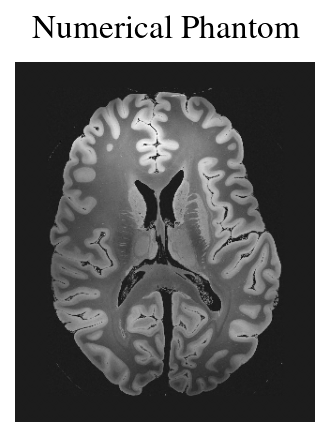

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(1.0, 1.25))
ax.imshow(ph, cmap='gray')
ax.axis('off');
ax.set_title("Numerical Phantom", fontsize=8);
fig.subplots_adjust(left=0, right=1, bottom=0, top=1);

In [7]:
# ----- simulation parameters ----- #

epi_fac_max = 16
epi_fac = 16

snr = 10.0

simul_param_range_tran = 0.20
simul_param_range_rot_deg = 2.0
rand_seed = 42

In [8]:
# ----- prepare simulation ----- #

rng = np.random.default_rng(rand_seed)
ny = sz_im[0]
nacq = ny // epi_fac
n_beat = nacq

ks = np.zeros((nacq, epi_fac), dtype="int32")
pe_indices_temp = np.arange(0, ny, nacq)
for i in range(nacq):
    ks[i] = i + pe_indices_temp

ws = np.ones_like(ks, dtype="float32")

roi_slice = tuple(slice(None) for _ in range(2))
sz_crop = sz_im

sense_op = Tran2DSenseOperator(sz_im, ks, sens, gpu_id, stream)
recon_op = Tran2DReconstructor(
    ncoil=ncoil,
    sz_im=sz_im,
    sz_crop=sz_crop,
    roi_slice=roi_slice,
    gpu_id=gpu_id,
    stream=stream,
)

data_gt = sense_op.forward(ph).reshape(sense_op.shape_data)
recon_op.prep(data_gt, ks, ws)
sos_gt = recon_op.recon(to_host=True)

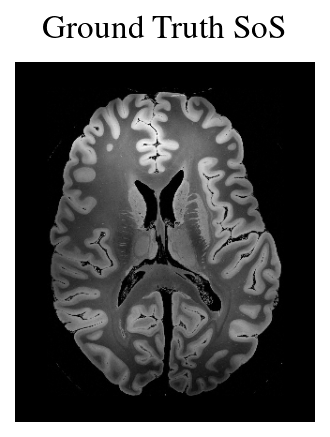

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(1.0, 1.25))
ax.imshow(sos_gt, cmap='gray')
ax.axis('off')
ax.set_title("Ground Truth SoS", fontsize=8);
fig.subplots_adjust(left=0, right=1, bottom=0, top=1);

In [10]:
# ----- simulate noise ----- #

cov = make_cov_ring(ncoil, rho=rho)

if np.isfinite(snr):
    noise_ksp_scaled, alpha = get_kspace_noise_multicoil(
        data_gt, ks, ws, snr, recon_op, mask, cov, rng
    )
else:
    noise_ksp_scaled = np.zeros_like(data_gt)
    alpha = 0

recon_op.prep(data_gt + noise_ksp_scaled, ks, ws)
sos_gt_n = recon_op.recon(to_host=True)

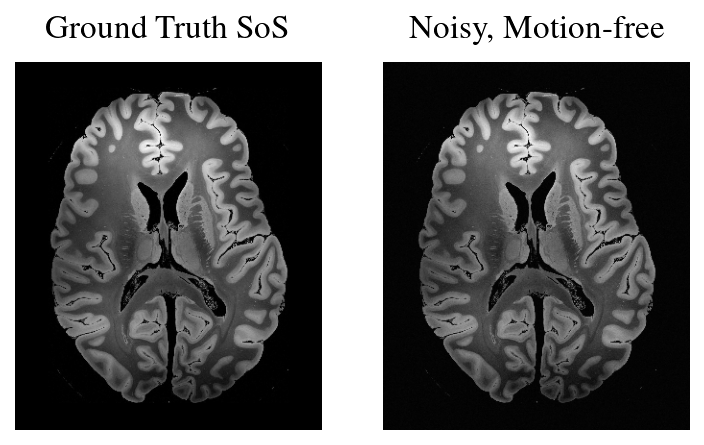

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(2.25, 1.25))
im0 = axes[0].imshow(sos_gt, cmap='gray')
im1 = axes[1].imshow(sos_gt_n, cmap='gray')
axes[0].axis('off')
axes[1].axis('off');
axes[0].set_title("Ground Truth SoS", fontsize=8);
axes[1].set_title("Noisy, Motion-free", fontsize=8);
fig.subplots_adjust(left=0, right=1, bottom=0, top=1);

In [12]:
# ----- simulate motion ----- #

tran_x_full, tran_y_full, rot_full = get_rigid2d_motion_params(
    ny, epi_fac_max, simul_param_range_tran, simul_param_range_rot_deg, rng
)

tran_x_gt = tran_x_full[:nacq]
tran_y_gt = tran_y_full[:nacq]
rot_gt = np.zeros(nacq, dtype="float32")

tran_x_gt -= np.mean(tran_x_gt)
tran_y_gt -= np.mean(tran_y_gt)

# add linear phase and noise

spacing = res[:2][::-1]
motion_op = Tran2DMotionOp(sz_im, spacing)

data = np.zeros_like(data_gt)
for i in range(nacq):
    data[:, i] = motion_op.apply_translation(
        data_gt[:, i] + noise_ksp_scaled[:, i],
        ks[i],
        np.array([tran_x_gt[i], tran_y_gt[i], 0], dtype="float32")
    )

recon_op.prep(data, ks, ws)
sos = recon_op.recon(to_host=True)

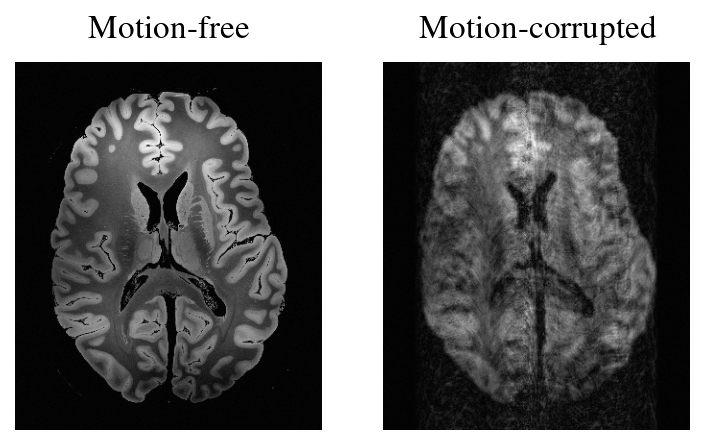

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(2.25, 1.25))
im0 = axes[0].imshow(sos_gt_n, cmap='gray')
im1 = axes[1].imshow(sos, cmap='gray')
axes[0].axis('off')
axes[1].axis('off');
axes[0].set_title("Motion-free", fontsize=8);
axes[1].set_title("Motion-corrupted", fontsize=8);
fig.subplots_adjust(left=0, right=1, bottom=0, top=1);

In [14]:
# ----- REACT parameters ----- #

niter = 10

mode = "tran"
ramp_niter = 5
ramp_type = "linear"

search_method = "BOBYQA"
search_tol = 1e-3

group_param = None
group_input = None

search_ub_tran_x = 0.20
search_ub_tran_y = 0.20

denoise_niter = 0
# denoise_niter = 25
# denoise_mu = 150

gpu_id = 0
rand_seed = 42
debug_prefix = None

In [15]:
# --- prepare search range --- #

if not isinstance(search_ub_tran_x, (tuple, list)):
    search_ub_tran_x = (search_ub_tran_x,) * niter
if not isinstance(search_ub_tran_y, (tuple, list)):
    search_ub_tran_y = (search_ub_tran_y,) * niter

search_ub_tran = []
for rx, ry in zip(search_ub_tran_x, search_ub_tran_y):
    search_ub_tran.append(np.array([rx, ry], dtype="float32"))  # yx order

In [16]:
# Disable initial grid search to avoid the current tran2d dimension mismatch.
init_grid_schedule = None

In [17]:
# --- prepare denoising --- #

if denoise_niter > 0:
    denoise_param = {}
    denoise_param["mu"] = denoise_mu
    denoise_param["lams"] = [2.0 * denoise_param["mu"]] * 2
    denoise_param["niter_inner"] = 1
    denoise_param["niter_outer"] = denoise_niter
    denoise_param["niter_solver"] = 2
    denoise_param["wavelet_full"] = False
    denoise_param["gam"] = 0
    denoise_param["wavelet_name"] = ""
    denoise_param["economize_gpu"] = False
else:
    denoise_param = None

In [18]:
# check denoising level

if denoise_param is not None and denoise_param["niter_outer"] > 0:
    from splitbregman.core import SplitBregman

    split_bregman = SplitBregman(
        model=Identity(
            int(np.prod(sos_gt.shape)),
            is_complex=False,
            gpu_id=gpu_id,
            stream=stream,
        ),
        sz_im=sos_gt.shape,
        economize_gpu=False,
    )

    sos_gt_den = split_bregman.run(
        data=sos_gt,
        init=sos_gt,
        mu=denoise_param["mu"],
        lams=denoise_param["lams"],
        gam=denoise_param["gam"],
        niter_inner=denoise_param["niter_inner"],
        niter_outer=denoise_param["niter_outer"],
        niter_solver=denoise_param["niter_solver"],
        wavelet_name=denoise_param["wavelet_name"],
        wavelet_full=denoise_param["wavelet_full"],
    ).reshape(sos_gt.shape);
else:
    sos_gt_den = sos_gt.copy()

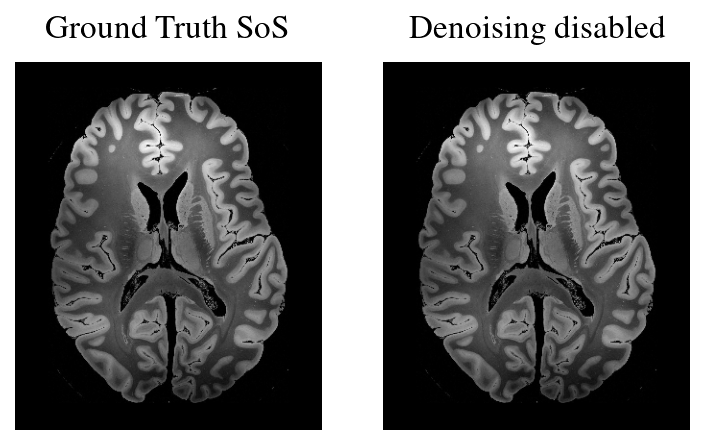

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(2.25, 1.25))
im0 = axes[0].imshow(sos_gt, cmap='gray')
im1 = axes[1].imshow(np.abs(sos_gt_den), cmap='gray')
axes[0].axis('off')
axes[1].axis('off')
axes[0].set_title("Ground Truth SoS", fontsize=8);
axes[1].set_title("Denoised" if denoise_param is not None and denoise_param["niter_outer"] > 0 else "Denoising disabled", fontsize=8);
fig.subplots_adjust(left=0, right=1, bottom=0, top=1);

In [20]:
# ---- run REACT ----- #

init_trans = np.zeros((n_beat, 3), dtype="float32")

trans, rotvecs, iter_costs, debug_returns = run_react(
    data,
    ks,
    mask=mask,
    init_trans=init_trans,
    niter=niter,
    search_ub_tran=search_ub_tran,
    search_tol=search_tol,
    group_param=group_param,
    group_input=group_input,
    init_grid_schedule=init_grid_schedule,
    sz_im=sz_im,
    res_2d=res[:2],
    denoise_param=denoise_param,
    ramp_niter=ramp_niter,
    ramp_type=ramp_type,
    gpu_id=gpu_id,
    rand_seed=rand_seed,
    search_method=search_method,
    verbose=True,
    debug_prefix=debug_prefix,
)

REACT: niter=10, method=BOBYQA, n_beat=24
iteration=0: mode=tran, learning_rate=0.16666666666666666, init_grid_spec=None
search_ub_tran=[0.2 0.2]
iteration=0, partition=0: n_group=24, min_group_size=1, max_group_size=1
iteration=0: cost=15.878398895263672, elapsed_time=1.080741332000116 seconds
iteration=1: mode=tran, learning_rate=0.3333333333333333, init_grid_spec=None
search_ub_tran=[0.2 0.2]
iteration=1, partition=0: n_group=24, min_group_size=1, max_group_size=1
iteration=1: cost=15.850181579589844, elapsed_time=1.14542902900007 seconds
iteration=2: mode=tran, learning_rate=0.5, init_grid_spec=None
search_ub_tran=[0.2 0.2]
iteration=2, partition=0: n_group=24, min_group_size=1, max_group_size=1
iteration=2: cost=15.752775192260742, elapsed_time=1.1931555450000815 seconds
iteration=3: mode=tran, learning_rate=0.6666666666666666, init_grid_spec=None
search_ub_tran=[0.2 0.2]
iteration=3, partition=0: n_group=24, min_group_size=1, max_group_size=1
iteration=3: cost=15.50001335144043, 

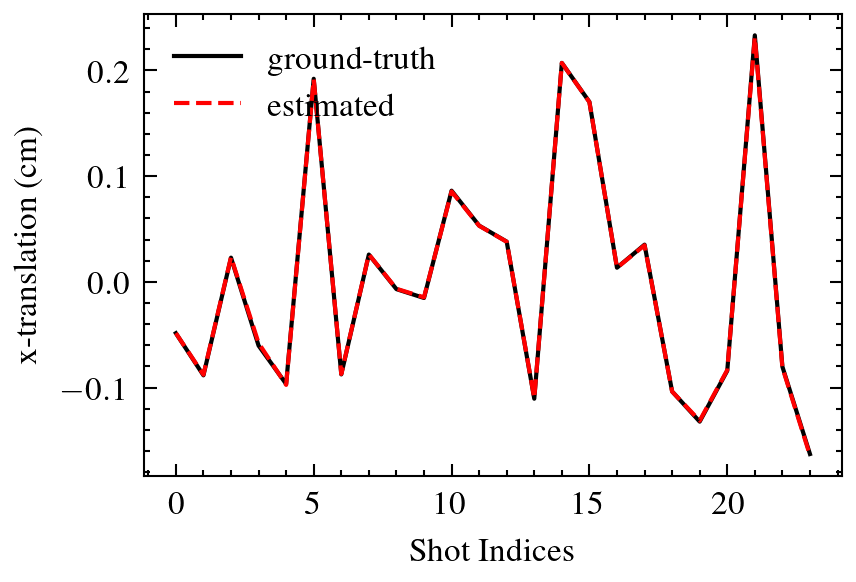

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(3, 2))
ax.plot(-tran_x_gt + np.mean(tran_x_gt), label="ground-truth");
ax.plot(trans[:, 0] - np.mean(trans[:, 0]), label="estimated");
ax.set_ylabel("x-translation (cm)");
ax.set_xlabel("Shot Indices");
ax.legend();

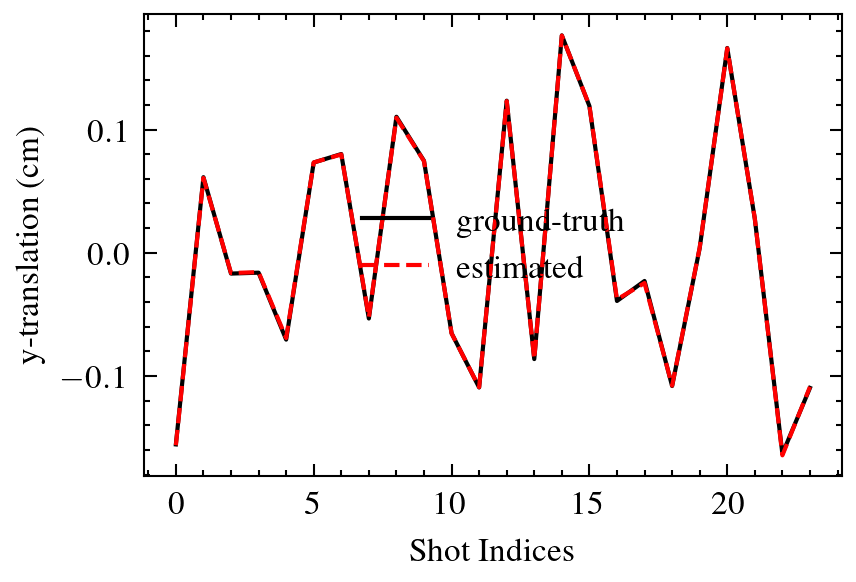

In [22]:
fig, ax = plt.subplots(1, 1, figsize=(3, 2))
ax.plot(-tran_y_gt + np.mean(tran_y_gt), label="ground-truth");
ax.plot(trans[:, 1] - np.mean(trans[:, 1]), label="estimated");
ax.set_ylabel("y-translation (cm)");
ax.set_xlabel("Shot Indices");
ax.legend();

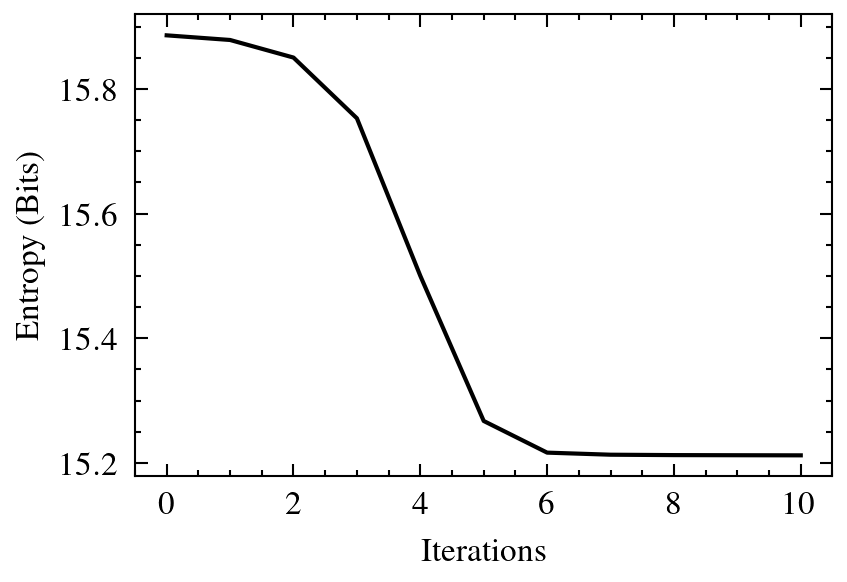

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(3, 2))
ax.plot(iter_costs);
ax.set_ylabel("Entropy (Bits)");
ax.set_xlabel("Iterations");

In [24]:
# ---- motion correction ---- #

data_c = np.zeros_like(data)
for i in range(nacq):
    data_c[:, i] = motion_op.apply_translation(
        data[:, i],
        ks[i],
        trans[i]
    )

recon_op.prep(data_c, ks, ws)
sos_c = recon_op.recon(to_host=True)

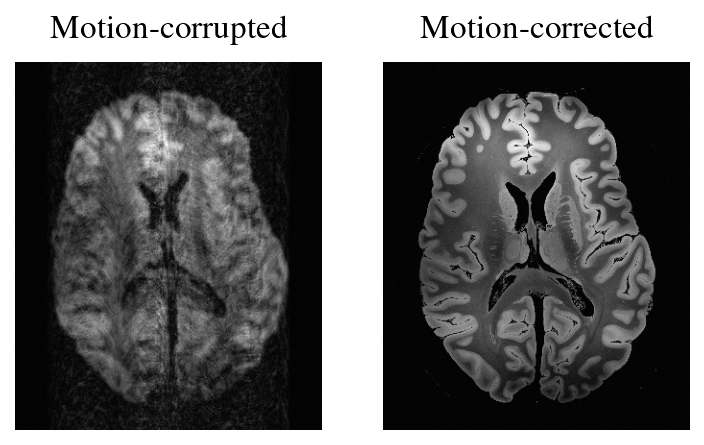

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(2.25, 1.25))
im0 = axes[0].imshow(sos, cmap='gray')
im1 = axes[1].imshow(sos_c, cmap='gray')
axes[0].axis('off')
axes[1].axis('off');
axes[0].set_title("Motion-corrupted", fontsize=8);
axes[1].set_title("Motion-corrected", fontsize=8);
fig.subplots_adjust(left=0, right=1, bottom=0, top=1);